In [1]:
####

# === Library Imports ===

# Standard Libraries
import os
import warnings
import logging
from datetime import datetime
from dataclasses import dataclass, field
from typing import Any, Dict, List, Callable, Optional

# Data Handling
import pandas as pd
import numpy as np
from openpyxl import Workbook
from openpyxl.styles import PatternFill, Alignment
import math

# Machine Learning
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import boxcox
from xgboost import XGBRegressor
import xgboost as xgb

# Models
import lightgbm as lgb
from catboost import CatBoostRegressor, Pool

# Visualization
import matplotlib.pyplot as plt
import shap

# SQL Utilities
from sqlalchemy import create_engine
from urllib.parse import quote_plus

# Custom Utilities
import utils.prediction_utils as pred
from utils import dictionaries as dictionary
from src.utils.query_dict import bucket_bounds, correction_factors
# from utils.logger import setup_logger  # Uncomment if needed

# === Jupyter Notebook Configuration ===

# Enable IPython to display all outputs for each cell
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

# === Warnings and Logging Configuration ===

# Suppress warnings
warnings.filterwarnings('ignore')
warnings.filterwarnings("ignore", category=UserWarning, module='lightgbm')

# Set logging for matplotlib and custom logger
plt.set_loglevel('warning')
logger = logging.getLogger("MyLogger")

# === Pandas Display Configuration ===
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)


In [2]:
TRAIN_END_DATE = '2023-08-01'
VAL_END_DATE = '2024-09-30'
TEST_START_DATE = '2024-10-01'

TARGET = 'ster_1+_total'
TARGET_GROUP = '25-67'

NUMERICAL_COLS = ['npo1_grp_daynight', 'npo1_grp_primetime',
                  'npo2_grp_daynight', 'npo2_grp_primetime',
                  'npo3_grp_daynight', 'npo3_grp_primetime',
                  'regio_grp_daynight', 'regio_grp_primetime',
                  'timef_olympic_period_overlap', 'timef_football_period_overlap',
                  'timef_duration_days',
                  'timef_start_month',
                  'timef_start_year',
                  'timef_start_week',
                ]

CATEGORICAL_COLS = [
                    # 'timef_start_season',
                    # 'timef_end_season'
                    ]

BOOLEAN_COLS = [
                'alcohol_kansspelen',
                'is_olympic_period',
                'is_football_period',
                ]

FEATURES = NUMERICAL_COLS + CATEGORICAL_COLS + BOOLEAN_COLS

In [51]:
@dataclass
class ModelTrainer:
    # SQL Query and Data Preparation
    target_group: str
    train_end_date: str
    val_end_date: str
    test_start_date: str
    features: List[str]
    target: str
    numerical_cols: List[str]
    categorical_cols: List[str]
    boolean_cols: List[str]

    bucket_bounds: dict = field(default_factory=lambda: bucket_bounds)
    correction_factors: dict = field(default_factory=lambda: correction_factors)

    # Preprocessing and Model Setup
    df: pd.DataFrame = None
    preprocessor: Optional[ColumnTransformer] = None
    feature_names: List[str] = field(default_factory=list)
    X_train: np.ndarray = None
    y_train: np.ndarray = None
    X_val: np.ndarray = None
    y_val: np.ndarray = None
    X_test: np.ndarray = None
    y_test: np.ndarray = None

    train_data: pd.DataFrame = field(init=False)
    val_data: pd.DataFrame = field(init=False)
    test_data: pd.DataFrame = field(init=False)

    # Model-related fields
    model: Any = None
    params: Dict[str, Any] = field(default_factory=dict)

    def __post_init__(self):
        # This runs when creating model class. Automatically fetches data and sets up preprocessor
        self.create_preprocessor()
        query = self.construct_query()
        df = self.query_to_df(query)
        self.df = self.prep_dataframe(df)
        self.apply_correction(self.df)
        self.split_and_preprocess()
        self.get_feature_names(self.preprocessor)

    def construct_query(self):
        """
        Constructs an SQL query to fetch the required data based on the target group.
        """
        target_group_str = (
            ', '.join([f"'{tg}'" for tg in self.target_group])
            if isinstance(self.target_group, (list, tuple))
            else f"'{self.target_group}'"
        )
        return f"""
            SELECT b.flight_id,
                   b.target_group,
                   f.advertiser,
                   f.product,
                   f.start_date,
                   f.end_date,
                   b.campaign_duration,
                   b.daypart,
                   f.mock_campaign,
                   f.alcohol_kansspelen,
                   b.ster_grp,
                   b.regio_grp,
                   b.npo1_grp,
                   b.npo2_grp,
                   b.npo3_grp,
                   b.[ster_1+]
            FROM [dbo].[tv.bereik_ster] b
            LEFT JOIN [dbo].[tv.flights_ster] f ON b.flight_id = f.flight_id
            WHERE b.ster_grp > 0
            AND target_group IN ({target_group_str})
            AND b.campaign_duration >= 7
            ORDER BY start_date;
        """

    def create_sql_alchemy_engine(self):
        """
        Creates and returns a SQLAlchemy engine for connecting to a SQL Server database.
        """
        quoted = quote_plus(
            "Driver={ODBC+Driver+17+for+SQL+Server};"
            "Server=tcp:stercampsql.database.windows.net;"
            "Database=SterCampNew;"
            "uid=stercampadmin;"
            f"pwd={os.getenv('SQLDB')}"
        )
        return create_engine(f"mssql+pyodbc:///?odbc_connect={quoted}")

    def query_to_df(self, query: str):
        """
        Executes the SQL query and returns the result as a DataFrame.
        """
        engine = self.create_sql_alchemy_engine()
        return pd.read_sql_query(query, engine)

    def prep_dataframe(self, df):
        df = df[["flight_id", "target_group", "start_date", "end_date", "advertiser", "product", "daypart", "mock_campaign", "alcohol_kansspelen",
                        "npo1_grp", "npo2_grp", "npo3_grp", "regio_grp", "ster_grp",
                        "ster_1+"]].reset_index(drop=True)

        df = (df.pivot_table(index=["flight_id", "target_group", "start_date", "end_date", 'advertiser', 'product', "mock_campaign", "alcohol_kansspelen"],
                            columns='daypart', fill_value=0.0,
                            values=['npo1_grp', 'npo2_grp', 'npo3_grp',
                                    'ster_grp', 'ster_1+', 'regio_grp'], aggfunc='sum').reset_index())


        df.columns = ["_".join(col) if col[1] else col[0] for col in df.columns.to_flat_index()]

        # Convert start_date and end_date to datetime objects and calculate required values
        df['start_date'] = pd.to_datetime(df['start_date'], format="%d%m%y", errors='coerce')
        df['end_date'] = pd.to_datetime(df['end_date'], format="%d%m%y", errors='coerce')

        # Apply function to create extra columns
        df['timef_start_month'] = df['start_date'].dt.month
        df['timef_end_month'] = df['end_date'].dt.month
        df['timef_start_year'] = df['start_date'].dt.year
        df['timef_end_year'] = df['end_date'].dt.year
        df['timef_start_week'] = df['start_date'].dt.strftime("%V").astype(int)
        df['timef_end_week'] = df['end_date'].dt.strftime("%V").astype(int)
        df['timef_start_day'] = df['start_date'].dt.day
        df['timef_end_day'] = df['end_date'].dt.day
        df['timef_duration_days'] = df.apply(lambda row: (row['end_date'] - row['start_date']).days + 1, axis=1)

        df['timef_start_season'] = df['timef_start_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                      'Spring' if month in [3, 4, 5] else
                                                      'Summer' if month in [6, 7, 8] else
                                                      'Autumn')
        df['timef_end_season'] = df['timef_end_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                    'Spring' if month in [3, 4, 5] else
                                                    'Summer' if month in [6, 7, 8] else
                                                    'Autumn')

        # Calculate total overlap with olympics and WK/EK
        df['timef_olympic_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.olympic_period_list))
        df['timef_football_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.football_wk_ek_list))

        # Create interaction features
        df['grp_olympic_overlap'] = df['ster_grp_total'] * df['timef_olympic_period_overlap']
        df['grp_football_overlap'] = df['ster_grp_total'] * df['timef_football_period_overlap']

        # Create binary indicators
        df['is_olympic_period'] = (df['timef_olympic_period_overlap'] > 0).astype(int)
        df['is_football_period'] = (df['timef_football_period_overlap'] > 0).astype(int)

        # Create a new column 'new_data' indicating old or new
        df['new_data'] = pd.cut(
            df['start_date'],
            bins=[pd.Timestamp.min, pd.to_datetime('2023-09-01'), pd.Timestamp.max],
            labels=[0, 1])

        # Add n random rows that have a base value of 0 GRPs and bereik
        non_grp_columns = ['start_date', 'end_date', 'timef_duration_days', 'timef_olympic_period_overlap', 'timef_football_period_overlap',
                            'timef_start_day', 'timef_end_day', 'timef_start_week', 'timef_end_week', 'timef_start_month',
                            'timef_end_month', 'timef_start_year', 'timef_end_year', 'timef_start_season', 'timef_end_season',
                            'target_group', 'advertiser', 'product', 'mock_campaign', 'alcohol_kansspelen', 'new_data']

        # Sample 600 random rows with 0 GRPs and bereik
        sampled_df = df.sample(n=600, random_state=42).reset_index(drop=True)
        sampled_df_zeroed = sampled_df.copy()
        for column in sampled_df_zeroed.columns:
            if column not in non_grp_columns:
                sampled_df_zeroed[column] = 0

        df_combined = pd.concat([df, sampled_df_zeroed], ignore_index=True)

        df = df_combined.sort_values(by=['start_date', 'advertiser', 'product', 'end_date'])

        # def shift_to_positive(column):
        #     if column.min() <= 0:
        #         return column + abs(column.min()) + 1
        #     return column

        # # Ensure positive values
        # df["npo3_grp_daynight"] = shift_to_positive(df["npo3_grp_daynight"])
        # df["npo3_grp_primetime"] = shift_to_positive(df["npo3_grp_primetime"])

        # # Apply Box-Cox transformation
        # transformed_data_daynight, lambda_value = boxcox(df["npo3_grp_daynight"])
        # transformed_data_primetime, lambda_value = boxcox(df["npo3_grp_primetime"])

        # # Store the transformed column and lambda
        # df["npo3_grp_daynight"] = transformed_data_daynight
        # df["npo3_grp_primetime"] = transformed_data_primetime

        ########## Filter Outliers ##########

        q_low = df['ster_grp_total'].quantile(0.01)
        q_hi  = df['ster_grp_total'].quantile(0.99)
        df = df[(df['ster_grp_total'] < q_hi) & (df['ster_grp_total'] > q_low)]

        q_low = df['ster_1+_total'].quantile(0.01)
        q_hi  = df['ster_1+_total'].quantile(0.99)
        df = df[(df['ster_1+_total'] < q_hi) & (df['ster_1+_total'] > q_low)]

        ##############################################

        return df

    def _get_bucket(self, target_group, ster_grp):
        """
        Determine the bucket for a given ster_grp value based on the bucket boundaries.

        :param target_group: The target group of the row.
        :param ster_grp: The ster_grp value of the row.
        :return: The bucket index (integer).
        """
        bounds = self.bucket_bounds.get(target_group, [0, np.inf])
        for i in range(len(bounds) - 1):
            if bounds[i] <= ster_grp < bounds[i + 1]:
                return i
        return len(bounds) - 2  # Default to the last bucket if not explicitly matched

    def apply_correction(self, df):
        """
        Apply the correction to the ster_1+ column in the DataFrame based on the bucket boundaries and correction factors.

        :param df: Input DataFrame containing 'target_group', 'ster_grp', 'ster_1+', and 'date'.
        :return: DataFrame with a new column 'corrected_ster_1+'.
        """
        def correct_row(row):
            if pd.to_datetime(row['start_date']) >= pd.Timestamp('2023-08-01'):
                return row['ster_1+_total']  # No correction applied after 08-2023
            bucket = self._get_bucket(row['target_group'], row['ster_grp_total'])
            correction_factor = self.correction_factors.get((row['target_group'], bucket), 1)
            if correction_factor is not None:
                return row['ster_1+_total'] * correction_factor
            return row['ster_1+_total']

        df['corrected_ster_1+'] = df.apply(correct_row, axis=1)
        # df['ster_1+_total'] = df.apply(correct_row, axis=1).round(1)

        return df

    def create_preprocessor(self):
        """
        Creates and configures the preprocessing pipeline.
        """
        transformers = []

        if self.numerical_cols:
            numerical_transformer = Pipeline(
                steps=[('imputer', SimpleImputer(strategy='mean'))]
            )
            transformers.append(('num', numerical_transformer, self.numerical_cols))

        if self.categorical_cols:
            categorical_transformer = Pipeline(
                steps=[
                    ('imputer', SimpleImputer(strategy='most_frequent')),
                    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first')),
                ]
            )
            transformers.append(('cat', categorical_transformer, self.categorical_cols))

        if self.boolean_cols:
            boolean_transformer = Pipeline(
                steps=[
                    ('int_conversion', FunctionTransformer(lambda x: x.astype(int), validate=False)),
                    ('imputer', SimpleImputer(strategy='most_frequent')),
                ]
            )
            transformers.append(('bool', boolean_transformer, self.boolean_cols))

        self.preprocessor = ColumnTransformer(transformers=transformers)

    def get_feature_names(self, preprocessor):
        feature_names = []

        # Get numerical feature names
        if 'num' in preprocessor.named_transformers_:
            feature_names += self.numerical_cols

        # Get categorical feature names
        if 'cat' in preprocessor.named_transformers_:
            encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
            cat_feature_names = encoder.get_feature_names_out(self.categorical_cols)
            feature_names += cat_feature_names.tolist()

        # Get boolean feature names
        if 'bool' in preprocessor.named_transformers_:
            feature_names += self.boolean_cols

        self.feature_names = feature_names

        return feature_names

    def split_and_preprocess(self):
        """
        Splits the data by date ranges, preprocesses, and transforms datasets.
        """
        df = self.df.copy()
        df['start_date'] = pd.to_datetime(df['start_date'])

        self.train_data = df[df['start_date'] < pd.Timestamp(self.train_end_date)]
        self.val_data = df[
            (df['start_date'] >= pd.Timestamp(self.train_end_date))
            & (df['start_date'] <= pd.Timestamp(self.val_end_date))
        ]
        self.test_data = df[df['start_date'] >= pd.Timestamp(self.test_start_date)]

        self.preprocessor.fit(self.train_data[self.features])
        self.X_train = self.preprocessor.transform(self.train_data[self.features])
        self.y_train = self.train_data[self.target].values
        self.X_val = self.preprocessor.transform(self.val_data[self.features])
        self.y_val = self.val_data[self.target].values
        self.X_test = self.preprocessor.transform(self.test_data[self.features])
        self.y_test = self.test_data[self.target].values


In [52]:
trainer = ModelTrainer(
    target_group= TARGET_GROUP,
    train_end_date= TRAIN_END_DATE,
    val_end_date= VAL_END_DATE,
    test_start_date= TEST_START_DATE,
    features = FEATURES,
    target= TARGET,
    numerical_cols= NUMERICAL_COLS,
    categorical_cols= CATEGORICAL_COLS,
    boolean_cols= BOOLEAN_COLS
)

In [54]:
trainer.train_data.head(2)

trainer.test_data.head(2)

,flight_id,target_group,start_date,end_date,advertiser,product,mock_campaign,alcohol_kansspelen,npo1_grp_daynight,npo1_grp_primetime,npo1_grp_total,npo2_grp_daynight,npo2_grp_primetime,npo2_grp_total,npo3_grp_daynight,npo3_grp_primetime,npo3_grp_total,regio_grp_daynight,regio_grp_primetime,regio_grp_total,ster_1+_daynight,ster_1+_primetime,ster_1+_total,ster_grp_daynight,ster_grp_primetime,ster_grp_total,timef_start_month,timef_end_month,timef_start_year,timef_end_year,timef_start_week,timef_end_week,timef_start_day,timef_end_day,timef_duration_days,timef_start_season,timef_end_season,timef_olympic_period_overlap,timef_football_period_overlap,grp_olympic_overlap,grp_football_overlap,is_olympic_period,is_football_period,new_data,corrected_ster_1+
87366,b87d8a9a-025c-16e5-2dbe-02799026009e,25-67,2018-01-01,2018-01-13,Abn amro,Abn-amro,False,False,0.00,33.76,33.76,0.0,33.24,33.24,0.00,8.00,8.0,0.0,0.0,0.0,0.00,34.73,34.73,0.00,75.00,75.00,1,1,2018,2018,1,2,1,13,13,Winter,Winter,0,0,0.0,0.0,0,0,0,30.9097
69097,91b826e6-67fc-f44e-7c15-5eed5a086038,25-67,2018-01-01,2018-01-08,Achmea holding,Centraal beheer,True,False,3.82,0.00,3.82,0.0,2.54,2.54,0.48,5.72,6.2,0.0,0.0,0.0,4.45,7.36,11.27,4.29,8.26,12.55,1,1,2018,2018,1,2,1,8,8,Winter,Winter,0,0,0.0,0.0,0,0,0,10.9319


,flight_id,target_group,start_date,end_date,advertiser,product,mock_campaign,alcohol_kansspelen,npo1_grp_daynight,npo1_grp_primetime,npo1_grp_total,npo2_grp_daynight,npo2_grp_primetime,npo2_grp_total,npo3_grp_daynight,npo3_grp_primetime,npo3_grp_total,regio_grp_daynight,regio_grp_primetime,regio_grp_total,ster_1+_daynight,ster_1+_primetime,ster_1+_total,ster_grp_daynight,ster_grp_primetime,ster_grp_total,timef_start_month,timef_end_month,timef_start_year,timef_end_year,timef_start_week,timef_end_week,timef_start_day,timef_end_day,timef_duration_days,timef_start_season,timef_end_season,timef_olympic_period_overlap,timef_football_period_overlap,grp_olympic_overlap,grp_football_overlap,is_olympic_period,is_football_period,new_data,corrected_ster_1+
39511,5360f308-ca9a-3fc7-b4c2-625a3ebab39e,25-67,2024-10-01,2024-10-19,Abn amro,Abn-amro,True,False,37.14,30.75,67.89,8.13,0.23,8.36,1.04,5.45,6.49,0.14,0.22,0.36,18.70,23.67,33.57,46.46,36.65,83.10,10,10,2024,2024,40,42,1,19,19,Autumn,Autumn,0,0,0.0,0.0,0,0,1,33.57
36905,4dde5797-8252-01cf-2bec-c37a26d5f56a,25-67,2024-10-01,2024-10-27,Abn amro,Abn-amro,False,False,55.07,40.05,95.12,9.78,0.23,10.02,1.83,5.45,7.28,0.14,0.22,0.36,22.78,27.06,38.52,66.83,45.95,112.78,10,10,2024,2024,40,43,1,27,27,Autumn,Autumn,0,0,0.0,0.0,0,0,1,38.52


<Figure size 1000x600 with 0 Axes>

(array([3174., 4229., 4786., 4956., 5509., 5805., 6016., 6024., 6128.,
        6283., 5941., 5806., 5465., 5221., 4948., 4644., 4135., 3773.,
        3439., 3280., 2869., 2764., 2211., 2039., 1755., 1534., 1336.,
        1151.,  896.,  693.]),
 array([ 2.26      ,  4.53333333,  6.80666667,  9.08      , 11.35333333,
        13.62666667, 15.9       , 18.17333333, 20.44666667, 22.72      ,
        24.99333333, 27.26666667, 29.54      , 31.81333333, 34.08666667,
        36.36      , 38.63333333, 40.90666667, 43.18      , 45.45333333,
        47.72666667, 50.        , 52.27333333, 54.54666667, 56.82      ,
        59.09333333, 61.36666667, 63.64      , 65.91333333, 68.18666667,
        70.46      ]),
 <BarContainer object of 30 artists>)

(array([3245., 4396., 4938., 5190., 5944., 6312., 6636., 7480., 7140.,
        6681., 6622., 6349., 5800., 5337., 4759., 4063., 3617., 3365.,
        3183., 2985., 2602., 2289., 1917., 1758., 1422., 1237.,  951.,
         474.,   67.,   51.]),
 array([ 2.1922 ,  4.46546,  6.73872,  9.01198, 11.28524, 13.5585 ,
        15.83176, 18.10502, 20.37828, 22.65154, 24.9248 , 27.19806,
        29.47132, 31.74458, 34.01784, 36.2911 , 38.56436, 40.83762,
        43.11088, 45.38414, 47.6574 , 49.93066, 52.20392, 54.47718,
        56.75044, 59.0237 , 61.29696, 63.57022, 65.84348, 68.11674,
        70.39   ]),
 <BarContainer object of 30 artists>)

Text(0.5, 0, 'Values')

Text(0, 0.5, 'Frequency')

Text(0.5, 1.0, 'Histogram: ster_1+_total vs corrected_ster_1+')

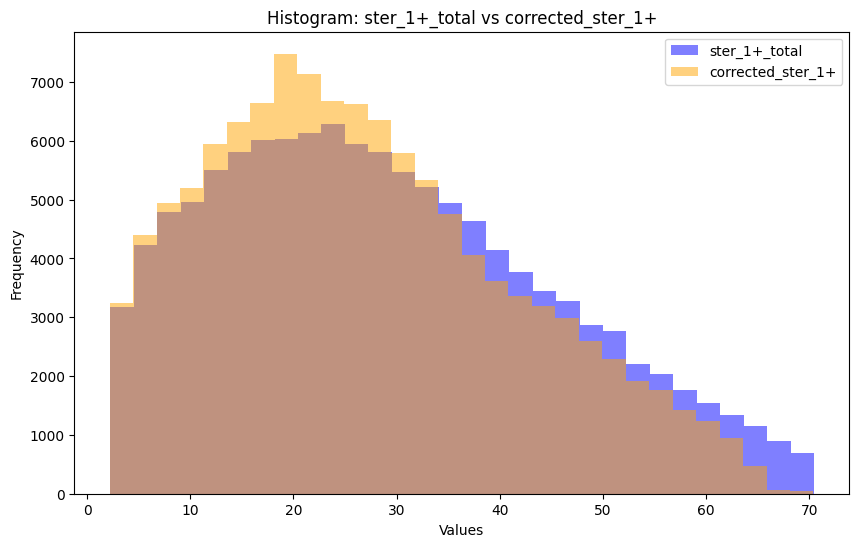

In [55]:
import matplotlib.pyplot as plt

# Create histograms for ster_1+_total and corrected_ster_1+
plt.figure(figsize=(10, 6))

# Plot histogram for ster_1+_total
plt.hist(trainer.df['ster_1+_total'], bins=30, alpha=0.5, label='ster_1+_total', color='blue')

# Plot histogram for corrected_ster_1+
plt.hist(trainer.df['corrected_ster_1+'], bins=30, alpha=0.5, label='corrected_ster_1+', color='orange')

# Add labels, legend, and title
plt.xlabel('Values')
plt.ylabel('Frequency')
plt.title('Histogram: ster_1+_total vs corrected_ster_1+')
plt.legend(loc='upper right')

# Show the plot
plt.show()

In [56]:
@dataclass
class ModelHandler:
    trainer: ModelTrainer  # Instance of the ModelTrainer class
    model_class: Callable  # Model class (e.g., CatBoostRegressor, LGBMRegressor, etc.)
    params: Dict[str, Any] = field(default_factory=dict)  # Model parameters
    best_params: dict = field(init=False, default_factory=dict)
    model: Any = None  # Initialized model instance
    evals_result: Dict[str, Dict[str, List[float]]] = field(default_factory=dict)  # For storing evaluation results

    def __post_init__(self):
        """
        Initialize the model instance with the provided parameters.
        """
        self.model = self.model_class(**self.params)

    def train(self, **kwargs):
        """
        Train the model using the training data from the ModelTrainer instance.
        Supports LightGBM, XGBoost, and CatBoost with early stopping and evaluation history.

        Parameters:
        - **kwargs: Additional keyword arguments for model training or callbacks.
        """
        # Use best parameters if available
        if hasattr(self, "best_params") and self.best_params:
            print(f"Using best parameters for {self.model_class.__name__}: {self.best_params}")
            self.params.update(self.best_params)
        else:
            print(f"Using default parameters for {self.model_class.__name__}.")

        print(f"Training {self.model_class.__name__}...")

        self.evals_result = {}

        if self.model_class.__name__ == "LGBMRegressor":
            # Convert data to LightGBM Datasets
            train_data = lgb.Dataset(self.trainer.X_train, label=self.trainer.y_train)
            val_data = lgb.Dataset(self.trainer.X_val, label=self.trainer.y_val, reference=train_data)

            def record_evals_result(env):
                """Custom callback to record evaluation results."""
                for data_name, eval_name, result, _ in env.evaluation_result_list:
                    if data_name not in self.evals_result:
                        self.evals_result[data_name] = {}
                    if eval_name not in self.evals_result[data_name]:
                        self.evals_result[data_name][eval_name] = []
                    self.evals_result[data_name][eval_name].append(result)

            # Initialize evaluation result storage
            self.evals_result = {}

            # Train the model with LightGBM's native API
            self.model = lgb.train(
                params=self.params,
                train_set=train_data,
                valid_sets=[train_data, val_data],  # Include both training and validation sets
                num_boost_round=kwargs.get("num_boost_round", 3000),
                callbacks=[
                    lgb.early_stopping(stopping_rounds=kwargs.get("early_stopping_rounds", 100)),
                    lgb.log_evaluation(period=kwargs.get("verbose", 100)),
                    record_evals_result
                ]
            )

            print(f"Best iteration: {self.model.best_iteration}")
            print(f"Best score on validation set: {self.model.best_score}")

        elif self.model_class.__name__ in ["XGBRegressor"]:
            self.model = self.model_class(**self.params)
            self.model.fit(
                self.trainer.X_train,
                self.trainer.y_train,
                eval_set=[
                    (self.trainer.X_train, "train"),  # Include training set
                    (self.trainer.X_val, "validation")  # Validation set
                ],
                verbose=True,
            )

            # Save evaluation results for plotting
            self.evals_result = self.model.evals_result_
            print(f"Best iteration: {self.model.best_iteration}")
            print(f"Best score on validation set: {self.model.best_score}")

        elif self.model_class.__name__ == "CatBoostRegressor":
            self.model.fit(
                self.trainer.X_train,
                self.trainer.y_train,
                eval_set=(self.trainer.X_val, self.trainer.y_val),
                early_stopping_rounds=kwargs.get("early_stopping_rounds", 100),
                verbose=kwargs.get("verbose", 100),
            )
            # Get evaluation results for all iterations
            self.evals_result = self.model.get_evals_result()

        else:
            # Fallback for other models
            self.model.fit(self.trainer.X_train, self.trainer.y_train, **kwargs)

        print(f"{self.model_class.__name__} training complete.")

    def plot_learning_curve(self):
        """
        Plot the learning curve using evaluation results (if available).
        """
        if not self.evals_result:
            print("No evaluation results to plot.")
            return

        print("Plotting learning curve...")
        for data_name, metrics in self.evals_result.items():
            for metric_name, results in metrics.items():
                plt.plot(results, label=f"{data_name} - {metric_name}")
        plt.xlabel("Iterations")
        plt.ylabel("Metric")
        plt.title(f"Learning Curve - {self.model_class.__name__}")
        plt.legend()
        plt.grid(True)
        plt.show()

    def predict(self, X):
        """
        Make predictions using the trained model.
        """
        if not self.model:
            raise ValueError("Model is not trained.")
        return self.model.predict(X)

    def evaluate(self, X, y):
        """
        Evaluate the model on the given data.
        """
        predictions = self.predict(X)
        mse = mean_squared_error(y, predictions)
        rmse = math.sqrt(mse)
        mae = mean_absolute_error(y, predictions)
        r2 = r2_score(y, predictions)
        return {"MSE": mse, "RMSE": rmse, "MAE": mae, "R²": r2}

    def display_metrics(self, y_train_true, y_train_pred, y_val_true, y_val_pred):
        """
        Display regression metrics (MAE, MSE, RMSE, R²) for both training and validation sets.

        Parameters:
        - y_train_true (array-like): True target values for the training set.
        - y_train_pred (array-like): Predicted target values for the training set.
        - y_val_true (array-like): True target values for the validation set.
        - y_val_pred (array-like): Predicted target values for the validation set.

        Returns:
        None (prints metrics directly)
        """
        # Training Metrics
        train_mae = mean_absolute_error(y_train_true, y_train_pred)
        train_mse = mean_squared_error(y_train_true, y_train_pred)
        train_rmse = np.sqrt(train_mse)
        train_r2 = r2_score(y_train_true, y_train_pred)

        # Validation Metrics
        val_mae = mean_absolute_error(y_val_true, y_val_pred)
        val_mse = mean_squared_error(y_val_true, y_val_pred)
        val_rmse = np.sqrt(val_mse)
        val_r2 = r2_score(y_val_true, y_val_pred)

        # Display Metrics
        print("Training Set Metrics:")
        print(f"  MAE: {train_mae:.4f}")
        print(f"  MSE: {train_mse:.4f}")
        print(f"  RMSE: {train_rmse:.4f}")
        print(f"  R²: {train_r2:.4f}")

        print("\nValidation Set Metrics:")
        print(f"  MAE: {val_mae:.4f}")
        print(f"  MSE: {val_mse:.4f}")
        print(f"  RMSE: {val_rmse:.4f}")
        print(f"  R²: {val_r2:.4f}")

    def tune_hyperparameters(self, param_grid: Dict[str, List[Any]], n_iter: int = 10, cv: int = 5, scoring: str = 'neg_mean_squared_error'):
        """
        Perform hyperparameter tuning using RandomizedSearchCV.
        """
        print(f"Tuning hyperparameters for {self.model_class.__name__}...")
        search = RandomizedSearchCV(
            estimator=self.model_class(),
            param_distributions=param_grid,
            n_iter=n_iter,
            scoring=scoring,
            cv=cv,
            verbose=1,
            random_state=42,
            n_jobs=-1
        )
        search.fit(self.trainer.X_train, self.trainer.y_train)
        self.model = search.best_estimator_
        self.best_params = search.best_params_
        print(f"Best parameters: {self.best_params}")

    def predict_and_export_to_excel(self, model, file_path="test_predictions.xlsx"):
        """
        Predicts on self.test_data and exports the results, including target, prediction, and residuals, to an Excel file.

        Parameters:
        - file_path (str): The path to save the Excel file. Default is "test_predictions.xlsx".
        """
        if type(model) == lightgbm.basic.Booster:
            model_prefix = "lgb"
        elif type(model) == xgboost.core.Booster:
            model_prefix = "xgb"
        elif type(model) == catboost.core.CatBoostRegressor:
            model_prefix = "cat"

        df_test = self.trainer.test_data.copy()

        # Predict on the test set
        predictions = model.predict(self.trainer.X_test)

        # Add predictions and residuals to the test dataframe
        df_test[f"prediction_{model_prefix}"] = predictions
        df_test[self.target] = self.trainer.y_test.flatten()
        df_test[f"residual_{model_prefix}"] = df_test[self.trainer.target] - df_test[f"prediction_{model_prefix}"]

        # Round the numerical values for better readability
        df_test[[f"prediction_{model_prefix}", self.trainer.target, f"residual_{model_prefix}"]] = df_test[[f"prediction_{model_prefix}", self.trainer.target, f"residual_{model_prefix}"]].round(2)

        # Select relevant columns
        df_test = df_test[[
            'flight_id', 'target_group', 'start_date', 'end_date', 'timef_duration_days', 'advertiser',
            'product', 'alcohol_kansspelen', 'npo1_grp_daynight',
            'npo1_grp_primetime', 'npo1_grp_total', 'npo2_grp_daynight',
            'npo2_grp_primetime', 'npo2_grp_total', 'npo3_grp_daynight',
            'npo3_grp_primetime', 'npo3_grp_total', 'regio_grp_daynight',
            'regio_grp_primetime', 'regio_grp_total', 'ster_grp_total',
            'ster_1+_total', 'prediction_lgb', 'residual_lgb'
        ]]

        # Calculate metrics
        test_mae = mean_absolute_error(self.trainer.y_test, predictions)
        test_mse = mean_squared_error(self.trainer.y_test, predictions)
        test_rmse = np.sqrt(test_mse)
        test_r2 = r2_score(self.trainer.y_test, predictions)

        # Display Metrics
        print("Test Set Metrics:")
        print(f"  MAE: {test_mae:.4f}")
        print(f"  MSE: {test_mse:.4f}")
        print(f"  RMSE: {test_rmse:.4f}")
        print(f"  R²: {test_r2:.4f}")

        df_test.to_excel(file_path, index = False)


## LGBM Regressor

In [62]:
param_grid = {
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "n_estimators": [100, 200, 300, 500, 800, 1000],
    "max_depth": [3, 5, 8, 12, 15, -1],
    "num_leaves": [15, 31, 50, 70, 100, 150],
    "min_child_samples": [10, 20, 50, 100],
    "min_child_weight": [1e-3, 1e-2, 0.1, 1.0],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_alpha": [0.5, 1.0, 1.5, 2.0],
    "reg_lambda": [0.0, 0.1, 0.5, 1.0, 1.5],
    "boosting_type": ["gbdt", "dart", "goss"],
    "objective": ["regression"]
}

lgb_handler = ModelHandler(
    trainer=trainer,
    model_class=lgb.LGBMRegressor,
    params=param_grid
)

In [63]:
lgb_handler.tune_hyperparameters(param_grid=param_grid, n_iter=30)
metrics = lgb_handler.evaluate(trainer.X_test, trainer.y_test)
print("LightGBM Metrics After Tuning:", metrics)

Tuning hyperparameters for LGBMRegressor...
Fitting 5 folds for each of 30 candidates, totalling 150 fits
[LightGBM] [Warning] Found boosting=goss. For backwards compatibility reasons, LightGBM interprets this as boosting=gbdt, data_sample_strategy=goss.To suppress this warning, set data_sample_strategy=goss instead.
[LightGBM] [Warning] Found boosting=goss. For backwards compatibility reasons, LightGBM interprets this as boosting=gbdt, data_sample_strategy=goss.To suppress this warning, set data_sample_strategy=goss instead.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002538 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1693
[LightGBM] [Info] Number of data points in the train set: 97215, number of used features: 13
[LightGBM] [Info] Using GOSS
[LightGBM] [Info] Start training from score 29.668959
Best parameters: {'subsample': 0

In [ ]:
lgb_handler.best_params = {'subsample': 1.0,
 'reg_lambda': 2.0,
 'reg_alpha': 0.8,
 'objective': 'regression',
 'num_leaves': 100,
 'n_estimators': 600,
 'min_child_weight': 0.001,
 'min_child_samples': 20,
 'max_depth': 8,
 'learning_rate': 0.03,
 'colsample_bytree': 0.6,
 "boosting_type": "gbdt",
 "data_sample_strategy": "goss"}

# Best parameters: {'subsample': 0.8, 'reg_lambda': 1.5, 'reg_alpha': 2.0, 'objective': 'regression', 'num_leaves': 50, 'n_estimators': 200, 'min_child_weight': 0.01, 'min_child_samples': 20, 'max_depth': -1, 'learning_rate': 0.05, 'colsample_bytree': 0.8, 'boosting_type': 'goss'}

Using best parameters for LGBMRegressor: {'subsample': 0.8, 'reg_lambda': 1.5, 'reg_alpha': 2.0, 'objective': 'regression', 'num_leaves': 50, 'n_estimators': 200, 'min_child_weight': 0.01, 'min_child_samples': 20, 'max_depth': -1, 'learning_rate': 0.05, 'colsample_bytree': 0.8, 'boosting_type': 'goss'}
Training LGBMRegressor...
[LightGBM] [Warning] Found boosting=goss. For backwards compatibility reasons, LightGBM interprets this as boosting=gbdt, data_sample_strategy=goss.To suppress this warning, set data_sample_strategy=goss instead.
[LightGBM] [Warning] Found boosting=goss. For backwards compatibility reasons, LightGBM interprets this as boosting=gbdt, data_sample_strategy=goss.To suppress this warning, set data_sample_strategy=goss instead.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001603 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] 

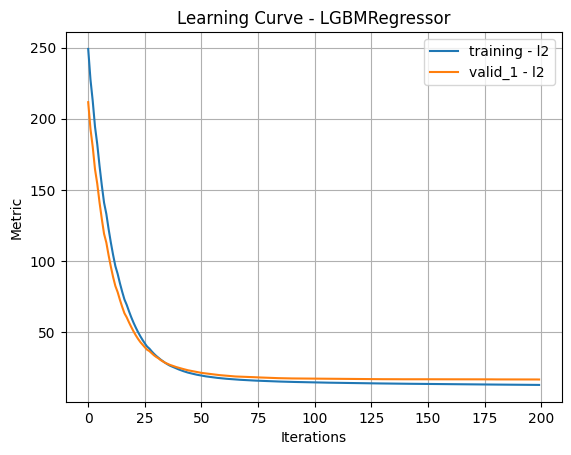

In [64]:
lgb_handler.train(
    eval_metric="rmse",
    early_stopping_rounds=50,
    verbose=100
)

lgb_handler.plot_learning_curve()

In [65]:
# Assuming predictions and true labels are stored in these variables
y_train_pred = lgb_handler.model.predict(trainer.X_train)
y_val_pred = lgb_handler.model.predict(trainer.X_val)

# Call the display_metrics function
lgb_handler.display_metrics(trainer.y_train, y_train_pred, trainer.y_val, y_val_pred)

Training Set Metrics:
  MAE: 2.7052
  MSE: 13.0303
  RMSE: 3.6097
  R²: 0.9508

Validation Set Metrics:
  MAE: 2.9020
  MSE: 16.8302
  RMSE: 4.1025
  R²: 0.9202


## XGBRegressor

In [46]:
# param_grid = {
#     "learning_rate": [0.01, 0.05, 0.1, 0.2],         # Step size shrinkage
#     "n_estimators": [100, 200, 300, 500, 800],      # Number of boosting rounds
#     "max_depth": [3, 5, 7, 10],                    # Maximum depth of a tree
#     "min_child_weight": [1, 5, 10],                # Minimum sum of instance weight (hessian) needed in a child
#     "subsample": [0.6, 0.8, 1.0],                  # Fraction of samples used for training
#     "colsample_bytree": [0.6, 0.8, 1.0],           # Fraction of features used per tree
#     "gamma": [0, 0.1, 0.2, 0.5],                   # Minimum loss reduction to make a split
#     "reg_alpha": [0, 0.1, 0.5, 1.0],               # L1 regularization term
#     "reg_lambda": [1.0, 2.0, 3.0],                 # L2 regularization term
#     "objective": ["reg:squarederror"],             # Use squared error for regression
#     "booster": ["gbtree", "dart"],                 # Type of booster to use
#     "tree_method": ["auto", "hist", "exact"],      # Tree construction method
#     "scale_pos_weight": [1],                       # Balance for imbalanced datasets
# }

## Used for tuning
param_grid = {
    "learning_rate": [0.02, 0.03, 0.04, 0.05],        # Focused around the best rate
    "n_estimators": [600, 800, 1000],                # Explore slightly fewer and more rounds
    "max_depth": [4, 5, 6],                          # Narrow range around the best depth
    "min_child_weight": [1, 2, 3],                   # Slightly higher regularization values
    "subsample": [0.7, 0.8, 0.9],                    # Focus near the best subsample
    "colsample_bytree": [0.5, 0.6, 0.7],             # Explore values around the best
    "reg_alpha": [0.3, 0.5, 0.7],                    # Narrow range around the best alpha
    "reg_lambda": [1.5, 2.0, 2.5],                   # Slightly broaden the lambda range
    "gamma": [0, 0.1, 0.2],                          # Small values for split regularization
    "tree_method": ["hist"],                         # Fixed as it performed best
    "objective": ["reg:squarederror"],               # Fixed for regression
    "scale_pos_weight": [1],                         # Fixed for balanced dataset
}

## Just use for training
# param_grid = {
#     "n_estimators": 500,
#     "learning_rate": 0.05,
#     "max_depth": 8,
#     "eval_metric": "rmse",
#     "early_stopping_rounds": 20,
# }

xgb_handler = ModelHandler(
    trainer=trainer,
    model_class=XGBRegressor,
    params=param_grid
)

In [ ]:
# xgb_handler.tune_hyperparameters(param_grid=param_grid, n_iter=20)
# metrics = xgb_handler.evaluate(trainer.X_test, trainer.y_test)
# print("XGBRegressor Metrics After Tuning:", metrics)


In [ ]:
# def custom_objective(self, y_true, y_pred):
#     """Custom loss function to penalize overestimation."""
#     residual = y_pred - y_true  # Residuals (difference between prediction and true value)
#     grad = residual * (residual > 0) * 2  # Penalize overestimation more heavily
#     hess = 2 * (residual > 0)  # Second derivative (constant in this case)
#     return grad, hess

xgb_handler.best_params = {'tree_method': 'hist',
 'subsample': 0.7,
 'scale_pos_weight': 1,
 'reg_lambda': 1.5,
 'reg_alpha': 0.3,
 'objective': 'reg:squarederror',
 'n_estimators': 2000,
 'min_child_weight': 1,
 'max_depth': 6,
 'learning_rate': 0.03,
 'gamma': 0.2,
 'colsample_bytree': 0.6,
 'eval_metric': 'rmse',
 'early_stopping_rounds': 20}


In [48]:
xgb_handler.train()
xgb_handler.plot_learning_curve()

Using best parameters for XGBRegressor: {'tree_method': 'hist', 'subsample': 0.7, 'scale_pos_weight': 1, 'reg_lambda': 1.5, 'reg_alpha': 0.3, 'objective': 'reg:squarederror', 'n_estimators': 2000, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.03, 'gamma': 0.2, 'colsample_bytree': 0.6, 'eval_metric': 'rmse', 'early_stopping_rounds': 20}
Training XGBRegressor...


TypeError: ('Unsupported type for label', "<class 'str'>")

In [49]:
# Assuming predictions and true labels are stored in these variables
y_train_pred = xgb_handler.model.predict(trainer.X_train)
y_val_pred = xgb_handler.model.predict(trainer.X_val)

# Call the display_metrics function
xgb_handler.display_metrics(trainer.y_train, y_train_pred, trainer.y_val, y_val_pred)

NotFittedError: need to call fit or load_model beforehand

## CatBoost

Using default parameters for CatBoostRegressor.
Training CatBoostRegressor...
0:	learn: 16.1361683	test: 14.8993285	best: 14.8993285 (0)	total: 63ms	remaining: 31.4s
100:	learn: 7.5169188	test: 7.1231272	best: 7.1231272 (100)	total: 5.59s	remaining: 22.1s
200:	learn: 4.8596890	test: 4.9937624	best: 4.9937624 (200)	total: 11s	remaining: 16.4s
300:	learn: 4.1555525	test: 4.5210013	best: 4.5210013 (300)	total: 16.7s	remaining: 11.1s
400:	learn: 3.9277751	test: 4.4008564	best: 4.4008564 (400)	total: 22.5s	remaining: 5.57s
499:	learn: 3.8108165	test: 4.3563180	best: 4.3563180 (499)	total: 28.2s	remaining: 0us

bestTest = 4.356318033
bestIteration = 499

CatBoostRegressor training complete.
CatBoost Metrics: {'MSE': 12.520240058026873, 'RMSE': 3.5383951246330407, 'MAE': 2.569741735525061, 'R²': 0.9197565316482224}
Plotting learning curve...


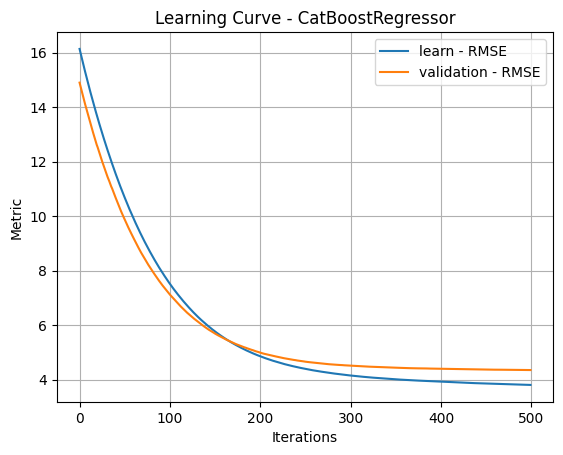

In [40]:
from catboost import CatBoostRegressor

cat_params = {
    "learning_rate": 0.01,
    "iterations": 500,
    "depth": 12,
    "random_state": 42,
    "verbose": 1
}

cat_handler = ModelHandler(
    trainer=trainer,
    model_class=CatBoostRegressor,
    params=cat_params
)

cat_handler.train()
metrics = cat_handler.evaluate(trainer.X_test, trainer.y_test)
print("CatBoost Metrics:", metrics)

cat_handler.plot_learning_curve()

In [ ]:
print(cat_handler.evals_result)

In [41]:
# Assuming predictions and true labels are stored in these variables
y_train_pred = cat_handler.model.predict(trainer.X_train)
y_val_pred = cat_handler.model.predict(trainer.X_val)

# Call the display_metrics function
cat_handler.display_metrics(trainer.y_train, y_train_pred, trainer.y_val, y_val_pred)

Training Set Metrics:
  MAE: 2.8736
  MSE: 14.5223
  RMSE: 3.8108
  R²: 0.9452

Validation Set Metrics:
  MAE: 3.0220
  MSE: 18.9775
  RMSE: 4.3563
  R²: 0.9100


## Predictions

In [ ]:
for model, model_name in zip([cat_handler, xgb_handler, lgb_handler], ["cat", "xgb", "lgb"]):
    df_test = trainer.test_data.copy()

    # Predict on the test set
    predictions = model.model.predict(trainer.X_test)

    # Add predictions and residuals to the test dataframe
    df_test[f"prediction_{model_name}"] = predictions
    df_test[trainer.target] = trainer.y_test.flatten()
    df_test[f"residual_{model_name}"] = df_test[trainer.target] - df_test[f"prediction_{model_name}"]

    # Round numerical values for readability
    df_test[[f"prediction_{model_name}", trainer.target, f"residual_{model_name}"]] = df_test[
        [f"prediction_{model_name}", trainer.target, f"residual_{model_name}"]
    ].round(2)

    # Plot residuals
    plt.figure(figsize=(7, 5))
    plt.scatter(df_test[trainer.target], df_test[f"residual_{model_name}"], alpha=0.6, label="Residuals")
    plt.axhline(0, color='red', linestyle='--', label="Zero Error Line")
    plt.xlabel("True Values")
    plt.ylabel("Residuals")
    plt.title(f"Residual Plot for {model_name} Model")
    plt.legend()
    plt.grid(True)
    plt.show();  # Add semicolon here to suppress the output


NameError: name 'xgb_handler' is not defined